# What Counts as Intelligence?

*The Mathematics of Machine Intelligence · Chapter 33*

Take a benchmark score apart, and see what one number carries and what has to travel with it.

These pages illustrate the mathematics. Read the saved figures and calculations in order, or open [the interactive browser edition](reader.html) to change the examples. No code editing is needed. Every figure is computed from the chapter's own equations or from a disclosed simulation; a simulation is not a measurement, and the mathematics of a brain is a model.

Ask which tasks, with what weights, on which set, under which harness and effort, on which date. Ask for the profile before the total. Check whether a part of the input alone predicts the answer, whether scores that rise together could come from overlapping causes, and whether the comparison with people was matched. Say that a total is not the thing it names.

<details><summary>Reproducing these calculations</summary>

The optional calculation cells use Python with NumPy and Matplotlib. All inputs, random seeds and functions are included in this file. The figures below are saved, so running these cells is optional.

</details>

In [1]:
import io
import math
import re
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cycler import cycler
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#7d8588', 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'xtick.color': '#52606b', 'ytick.color': '#52606b', 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'grid.alpha': 0.2, 'lines.linewidth': 2, 'svg.fonttype': 'path', 'axes.unicode_minus': False})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37', '#677341'])

def clean_display_text(text):
    """Remove signed zero only after an explicitly formatted value rounds to zero."""
    return re.sub(r"(?<![\w.])-(?:0+(?:\.0*)?|\.0+)(?:[eE][+-]?\d+)?(?![\w.])", "0", text)


def display_value(value):
    """One display policy for readers, saved notebooks and skill references."""
    if hasattr(value, "item") and getattr(value, "size", 1) == 1:
        value = value.item()
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError("Return undefined or infinity as a labeled string, not a nonfinite JSON value")
        return "0" if value == 0 else f"{value:.6g}"
    if isinstance(value, str):
        return clean_display_text(value)
    if isinstance(value, (list, tuple)):
        opening, closing = ("(", ")") if isinstance(value, tuple) else ("[", "]")
        return opening + ", ".join(str(display_value(v)) for v in value) + closing
    if isinstance(value, dict):
        return "{" + ", ".join(str(k) + ": " + str(display_value(v)) for k, v in value.items()) + "}"
    return value


"""Chapter 33, What Counts as Intelligence?: executable mathematics and reader-facing teaching content."""
import math
import numpy as np
import matplotlib.pyplot as plt
NAVY = '#17324d'
TEAL = '#147d86'
GOLD = '#d8a23c'
DARK_GOLD = '#8a5a0f'
TERRA = '#bf6045'
GREY = '#7d8588'

def sig(value, digits=3):
    """Three significant figures; values that are zero up to round-off show as 0."""
    value = float(value)
    if abs(value) < 1e-12:
        return '0'
    return f'{value:.{digits}g}'

def panels():
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout='constrained')
    for ax in axes:
        ax.grid(alpha=0.15)
    return (fig, axes)

def tag(ax, x, y, text, **kwargs):
    """A label with a white backing so it stays legible over lines."""
    kwargs.setdefault('fontsize', 10)
    kwargs.setdefault('ha', 'center')
    ax.text(x, y, text, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.5, 'alpha': 0.9}, **kwargs)

def ring(ax, x, y):
    ax.plot([x], [y], marker='o', markersize=11, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=6)
CAP = 1.15
HUMAN_MOVES = 20

def level_score(human_moves, agent_moves, finished=True, cap=CAP):
    """s = min((h / a)^2, cap); a level the agent does not finish scores zero."""
    if not (human_moves > 0 and agent_moves > 0):
        raise ValueError('Move counts must be positive.')
    if not finished:
        return 0.0
    return min((human_moves / agent_moves) ** 2, cap)

def level_picture(agent_moves=40, status='finished'):
    finished = status == 'finished'
    h = HUMAN_MOVES
    score = level_score(h, agent_moves, finished)
    raw = (h / agent_moves) ** 2
    fig, ax = panels()
    bars = ax[0].bar(['human\nbaseline', 'agent'], [h, agent_moves], color=[GREY, TEAL if finished else TERRA], width=0.5)
    for bar, v in zip(bars, [h, agent_moves]):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v + 1.5, f'{v:g} moves', va='bottom')
    shown = sig(100 * score) + ' percent' if finished else '0 (level not finished)'
    ax[0].text(0.5, 0.9, 'level score: ' + shown, transform=ax[0].transAxes, ha='center', fontsize=11, color=NAVY if finished else TERRA, bbox={'facecolor': 'white', 'edgecolor': GREY, 'pad': 3})
    ax[0].set(ylabel='moves on one level', title='Agent moves against the human baseline', ylim=(0, 105))
    ratios = np.linspace(0.4, 4.2, 400)
    ax[1].plot(ratios, [100 * min(1 / r ** 2, CAP) for r in ratios], color=TEAL, linewidth=2.5, label='score with the cap')
    ax[1].plot(ratios, [100 / r ** 2 for r in ratios], color=GREY, linewidth=1.4, linestyle='dotted', label='squared ratio, no cap')
    ax[1].axhline(100, color=GREY, linewidth=0.8)
    ring(ax[1], agent_moves / h, 100 * score)
    ax[1].set(xlabel='agent moves divided by human moves', ylabel='level score (percent)', title='Twice the moves, a quarter of the score', ylim=(-3, 230), xlim=(0.4, 4.2))
    ax[1].legend(fontsize=9, loc='upper right')
    metrics = {'Agent moves': agent_moves, 'Moves divided by human baseline': sig(agent_moves / h), 'Squared ratio (h/a)^2': sig(raw), 'Level score (percent)': sig(100 * score) if finished else '0 (level not finished)'}
    if finished:
        capped = ' The cap holds it at 115 percent.' if raw > CAP else ''
        summary = f'With {agent_moves} moves against a human baseline of {h}, the squared ratio is {sig(raw)} and the level scores {sig(100 * score)} percent.{capped}'
        calc = f's = min((h/a)^2, 1.15) = min(({h}/{agent_moves})^2, 1.15) = min({sig(raw)}, 1.15) = {sig(score)}.'
    else:
        summary = f'A level the agent does not finish scores zero, whatever its move count. At {agent_moves} moves the squared ratio would have been {sig(raw)}.'
        calc = f'Level not finished, so s = 0. (Had it finished: min(({h}/{agent_moves})^2, 1.15) = {sig(min(raw, CAP))}.)'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
LEVELS = 5

def environment_score(finished_count, move_ratio, levels=LEVELS):
    """Smaller of the weighted efficiency average and the weighted completion fraction; level number is the weight."""
    weights = np.arange(1, levels + 1, dtype=float)
    weights /= weights.sum()
    per_level = np.array([level_score(1.0, move_ratio, finished=k < finished_count) for k in range(levels)])
    done = np.array([k < finished_count for k in range(levels)], dtype=float)
    efficiency = float(weights @ per_level)
    completion = float(weights @ done)
    return {'weights': weights, 'per_level': per_level, 'efficiency': efficiency, 'completion': completion, 'score': min(efficiency, completion)}

def environment_picture(levels_done=3, move_ratio=1.0):
    data = environment_score(levels_done, move_ratio)
    fig, ax = panels()
    xs = np.arange(1, LEVELS + 1)
    heights = data['per_level'] * 100
    ax[0].bar(xs, heights, color=[TEAL if k <= levels_done else GREY for k in xs], alpha=0.9, width=0.6)
    for x, h, w in zip(xs, heights, data['weights']):
        tag(ax[0], x, h + 3, sig(h) if h else '0', va='bottom', fontsize=9)
    ax[0].set_xticks(xs)
    ax[0].set_xticklabels([f'{k}\n{k}/15' for k in xs], fontsize=8)
    ax[0].set(xlabel='level, and its weight below', ylabel='level score (percent)', title='Per-level scores in a five-level environment', ylim=(0, 140))
    ks = np.arange(0, LEVELS + 1)
    results = [environment_score(int(k), move_ratio) for k in ks]
    ax[1].plot(ks, [100 * r['score'] for r in results], color=NAVY, linewidth=5, label='environment score (smaller)', alpha=0.35)
    ax[1].plot(ks, [100 * r['completion'] for r in results], color=GOLD, linewidth=2, linestyle='dashed', label='weighted completion')
    ax[1].plot(ks, [100 * r['efficiency'] for r in results], color=TEAL, linewidth=2, linestyle='dotted', label='weighted efficiency average')
    ring(ax[1], levels_done, 100 * data['score'])
    ax[1].set(xlabel='levels finished (from level 1 up)', ylabel='percent', title='The smaller of two averages', ylim=(-3, 122))
    ax[1].legend(fontsize=8, loc='upper left')
    smaller = 'tie' if abs(data['efficiency'] - data['completion']) < 1e-12 else 'completion' if data['completion'] < data['efficiency'] else 'efficiency'
    metrics = {'Weighted efficiency average (percent)': sig(100 * data['efficiency']), 'Weighted completion (percent)': sig(100 * data['completion']), 'Environment score (percent)': sig(100 * data['score']), 'Which is smaller': smaller if smaller != 'tie' else 'neither (equal)'}
    per = sig(level_score(1.0, move_ratio))
    summary = f"Finishing {levels_done} of 5 levels at {sig(move_ratio)} of the human move count, each finished level scores {per}. Efficiency averages {sig(100 * data['efficiency'])} percent and completion {sig(100 * data['completion'])} percent, so the environment scores {sig(100 * data['score'])}."
    calc = f"Weights are the level numbers over 15. Efficiency = sum of weight x level score = {sig(data['efficiency'])}. Completion = sum of weight x finished = {sig(data['completion'])}. Score = min({sig(data['efficiency'])}, {sig(data['completion'])}) = {sig(data['score'])}."
    return (fig, metrics, {'summary': summary, 'calculation': calc})
EFFORTS = ['none', 'low', 'medium', 'high', 'xhigh', 'max']
STANDARD = {'none': 35.2, 'low': 17.5, 'medium': 38.6, 'high': 54.8, 'xhigh': 59.3, 'max': 62.7}
ADAPTER = {'none': 96.7, 'low': 98.0, 'medium': 98.4, 'high': 99.95, 'xhigh': 98.4, 'max': 98.6}

def harness_picture(effort='high'):
    std, ada = (STANDARD[effort], ADAPTER[effort])
    fig, ax = panels()
    x = np.arange(2)
    bars = ax[0].bar(['Standard\nharness', 'Provider Adapter\nharness'], [std, ada], color=[TERRA, TEAL], width=0.55)
    for bar, v in zip(bars, [std, ada]):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v + 1.5, sig(v, 4), va='bottom')
    ax[0].set(ylabel='score on the semi-private set (percent)', title=f'GPT-6 Astra at {effort} effort', ylim=(0, 118))
    idx = np.arange(len(EFFORTS))
    ax[1].plot(idx, [ADAPTER[e] for e in EFFORTS], color=TEAL, marker='o', linewidth=2, label='Provider Adapter')
    ax[1].plot(idx, [STANDARD[e] for e in EFFORTS], color=TERRA, marker='s', linewidth=2, label='Standard')
    ax[1].annotate('best Standard entry,\n62.7 at max', xy=(5, 62.7), xytext=(3.1, 45), fontsize=8, color=TERRA, arrowprops={'arrowstyle': '->', 'color': TERRA})
    ax[1].annotate('best Adapter entry,\n99.95 at high', xy=(3, 99.95), xytext=(0.2, 86), fontsize=8, color=TEAL, arrowprops={'arrowstyle': '->', 'color': TEAL})
    ring(ax[1], EFFORTS.index(effort), std)
    ring(ax[1], EFFORTS.index(effort), ada)
    ax[1].set_xticks(idx)
    ax[1].set_xticklabels(EFFORTS, fontsize=9)
    ax[1].set(xlabel='effort setting, none to max', ylabel='score (percent)', title='Adapter higher at all six settings', ylim=(0, 108))
    ax[1].legend(fontsize=9, loc='lower right')
    gap = ada - std
    metrics = {'Standard harness (percent)': sig(std, 4), 'Provider Adapter harness (percent)': sig(ada, 4), 'Gap at this effort (points)': sig(gap, 4), 'Adapter higher at all six settings': 'yes' if all((ADAPTER[e] > STANDARD[e] for e in EFFORTS)) else 'no'}
    summary = f'At {effort} effort the Standard harness scored {sig(std, 4)} and the Provider Adapter {sig(ada, 4)}, a gap of {sig(gap, 4)} points. The Adapter is higher at all six settings, and each entry is a single run on one date, so a score needs its harness, set and effort.'
    calc = f'Gap = {sig(ada, 4)} - {sig(std, 4)} = {sig(gap, 4)} points. The best entries differ in effort: Standard 62.7 at max, Adapter 99.95 at high, a gap of {sig(99.95 - 62.7, 4)} that mixes the harness effect with the effort setting.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
SCORES = {'P': (85.0, 35.0), 'Q': (45.0, 75.0)}

def weighted_average(scores, weights):
    """S = sum w_t r_t with nonnegative weights that sum to one."""
    weights = np.asarray(weights, dtype=float)
    if np.any(weights < 0) or abs(weights.sum() - 1) > 1e-09:
        raise ValueError('Weights must be nonnegative and sum to one.')
    return float(np.dot(weights, np.asarray(scores, dtype=float)))

def weighted_picture(weight_first=0.5):
    w = (weight_first, 1 - weight_first)
    p = weighted_average(SCORES['P'], w)
    q = weighted_average(SCORES['Q'], w)
    fig, ax = panels()
    xs = np.arange(2)
    ax[0].bar(xs - 0.18, SCORES['P'], width=0.34, color=TEAL, alpha=0.45, label='P, separate scores')
    ax[0].bar(xs + 0.18, SCORES['Q'], width=0.34, color=TERRA, alpha=0.45, label='Q, separate scores')
    ax[0].axhline(p, color=TEAL, linewidth=2.5, label=f'P average {sig(p)}')
    ax[0].axhline(q, color=TERRA, linewidth=2.5, linestyle='dashed', label=f'Q average {sig(q)}')
    ax[0].set_xticks(xs)
    ax[0].set_xticklabels(['first group of tasks', 'second group of tasks'], fontsize=9)
    ax[0].set(ylabel='score', title='Same scores, two averages', ylim=(0, 125))
    ax[0].legend(fontsize=8, loc='upper center', ncol=2)
    grid = np.linspace(0, 1, 101)
    ax[1].plot(grid, [weighted_average(SCORES['P'], (g, 1 - g)) for g in grid], color=TEAL, linewidth=2.2, label='P')
    ax[1].plot(grid, [weighted_average(SCORES['Q'], (g, 1 - g)) for g in grid], color=TERRA, linewidth=2.2, linestyle='dashed', label='Q')
    ring(ax[1], weight_first, p)
    ring(ax[1], weight_first, q)
    ax[1].axvline(0.5, color=GREY, linestyle='dotted', linewidth=1)
    tag(ax[1], 0.5, 82, 'tie at 0.5:\nboth 60', fontsize=9)
    ax[1].set(xlabel='weight on the first group', ylabel='weighted average', title='The order flips at one half', ylim=(30, 90), xlim=(0, 1))
    ax[1].legend(fontsize=9, loc='lower center')
    leader = 'neither (tie)' if abs(p - q) < 1e-09 else 'P' if p > q else 'Q'
    metrics = {'P weighted average': sig(p), 'Q weighted average': sig(q), 'Ahead': leader, 'Weight on the second group': sig(1 - weight_first)}
    summary = f'With weight {sig(weight_first)} on the first group and {sig(1 - weight_first)} on the second, P averages {sig(p)} and Q {sig(q)}. The separate scores never change; the weights decide the order, because they record which question was asked.'
    calc = f'P = {sig(weight_first)} x 85 + {sig(1 - weight_first)} x 35 = {sig(p)}. Q = {sig(weight_first)} x 45 + {sig(1 - weight_first)} x 75 = {sig(q)}. The difference is 80 x w - 40 = {sig(p - q)}, which is zero at w = 0.5.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
TESTS = 10
INCLUDE = np.linspace(0.15, 0.45, TESTS)
DICE_COUNTS = [40, 80, 145, 300, 1000, 5000]

def dice_table(dice, shared):
    """Correlations among ten tests whose scores are sums of independent dice.

    Each of `dice` dice enters test i with chance INCLUDE[i], at random. `shared` further dice enter every test.
    The correlation of two sums of independent unit-variance dice is (dice they share) / sqrt(dice in one x dice in the other).
    """
    rng = np.random.default_rng([33, dice, shared])
    entered = (rng.random((dice, TESTS)) < INCLUDE).astype(float)
    membership = np.vstack([entered, np.ones((shared, TESTS))])
    overlap = membership.T @ membership
    sizes = np.diag(overlap).copy()
    if np.any(sizes == 0):
        raise ValueError('A test drew no dice.')
    corr = overlap / np.sqrt(np.outer(sizes, sizes))
    in_every_test = int(entered.all(axis=1).sum()) + shared
    most_tests = int(membership.sum(axis=1).max())
    return (corr, in_every_test, most_tests)

def one_factor_fit(corr, iterations=500):
    """Best one-factor table by principal-axis iteration: loadings and the largest off-diagonal gap."""
    n = len(corr)
    off = ~np.eye(n, dtype=bool)
    communality = np.max(np.abs(corr - np.eye(n)), axis=1)
    loadings = np.sqrt(communality)
    for _ in range(iterations):
        reduced = corr.copy()
        np.fill_diagonal(reduced, communality)
        values, vectors = np.linalg.eigh(reduced)
        loadings = np.abs(vectors[:, -1]) * math.sqrt(max(values[-1], 0.0))
        communality = loadings ** 2
    gap = float(np.abs(corr - np.outer(loadings, loadings))[off].max())
    return (loadings, gap)

def dice_picture(dice=145, shared=0):
    corr, in_every, most = dice_table(dice, shared)
    loadings, gap = one_factor_fit(corr)
    off = ~np.eye(TESTS, dtype=bool)
    fig, ax = panels()
    image = ax[0].imshow(corr, vmin=0, vmax=1, cmap='Blues')
    ax[0].set_xticks(range(TESTS))
    ax[0].set_xticklabels(range(1, TESTS + 1), fontsize=8)
    ax[0].set_yticks(range(TESTS))
    ax[0].set_yticklabels(range(1, TESTS + 1), fontsize=8)
    ax[0].set(xlabel='test', ylabel='test', title='Correlations among ten dice-sum tests')
    ax[0].grid(False)
    fig.colorbar(image, ax=ax[0], shrink=0.8, label='correlation')
    for s, style, colour in [(0, 'solid', TEAL), (19, 'dashed', GOLD)]:
        gaps = [one_factor_fit(dice_table(d, s)[0])[1] for d in DICE_COUNTS]
        chosen = s == shared
        ax[1].plot(range(len(DICE_COUNTS)), gaps, color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.8, marker='o', markersize=4, label='no die shared by all ten' if s == 0 else '19 dice shared by all ten')
    ring(ax[1], DICE_COUNTS.index(dice), gap)
    ax[1].set_xticks(range(len(DICE_COUNTS)))
    ax[1].set_xticklabels([str(d) for d in DICE_COUNTS], fontsize=8)
    ax[1].set(xlabel='random dice in the pool', ylabel='largest gap from a one-factor table', title='More dice, closer to one factor', ylim=(0, 0.25))
    ax[1].legend(fontsize=8, loc='upper right')
    metrics = {'Dice entering all ten tests': in_every, 'Most tests any one die enters': most, 'Mean correlation between tests': sig(corr[off].mean()), 'Largest gap from a one-factor table': sig(gap)}
    summary = f'With {dice} random dice and {shared} shared, {in_every} dice enter all ten tests, the mean correlation is {sig(corr[off].mean())}, and the best one-factor table misses by at most {sig(gap)}. ' + ('A one-factor table summarizes these correlations although no die is common to all tests.' if in_every == 0 else 'Here some dice are common to all tests, so a common source exists by construction.')
    calc = f'Test i uses each die with chance 0.15 to 0.45 (ten values). Correlation = shared dice / sqrt(dice in one x dice in the other). A one-factor table has correlation = loading i x loading j; the best fit leaves a largest gap of {sig(gap)} (seeded draw).'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
MAJORITY, BLIND, EASY, HARD, OVERALL = (34.3, 67.0, 93.4, 72.7, 86.5)

def easy_hard_overall(blind_share_right, easy=EASY, hard=HARD):
    """Overall score as a weighted average of the Easy and Hard scores; the Easy share is the share the blind classifier got right."""
    if not 0 <= blind_share_right <= 1:
        raise ValueError('A share must lie between 0 and 1.')
    return blind_share_right * easy + (1 - blind_share_right) * hard

def blind_picture(blind_right=0.67):
    overall = easy_hard_overall(blind_right)
    fig, ax = panels()
    labels = ['always guess the\ncommon label', 'blind classifier\n(hypothesis only)', 'full model,\nEasy items', 'full model,\nHard items']
    values = [MAJORITY, BLIND, EASY, HARD]
    colours = [GREY, GOLD, TEAL, TERRA]
    bars = ax[0].bar(labels, values, color=colours, width=0.6)
    for bar, v in zip(bars, values):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v + 2, f'{v:.1f}', va='bottom')
    ax[0].tick_params(axis='x', labelsize=7.5)
    ax[0].set(ylabel='percent right', title='Scores quoted in the chapter', ylim=(0, 112))
    grid = np.linspace(0.343, 1, 100)
    ax[1].plot(grid, [easy_hard_overall(g) for g in grid], color=TEAL, linewidth=2.5, label='weighted average of Easy and Hard')
    ax[1].axhline(OVERALL, color=GREY, linestyle='dashed', linewidth=1.2, label='reported overall, 86.5')
    ax[1].axvline(0.67, color=GREY, linestyle='dotted', linewidth=1)
    ring(ax[1], blind_right, overall)
    ax[1].set(xlabel='share of items the blind classifier got right (the Easy share)', ylabel='full model, overall percent', title='Overall is an average of the two splits', ylim=(70, 96))
    ax[1].legend(fontsize=8, loc='upper left')
    metrics = {'Easy share': sig(blind_right), 'Hard share': sig(1 - blind_right), 'Weighted overall (percent)': sig(overall, 4), 'Reported overall (percent)': '86.5'}
    summary = f'If the blind classifier got {sig(100 * blind_right)} percent right, Easy items are that share and Hard the rest, so a model scoring 93.4 on Easy and 72.7 on Hard averages {sig(overall, 4)}. At 67.0 percent this is {sig(easy_hard_overall(0.67), 4)}, within 0.1 of the reported 86.5.'
    calc = f'Overall = share Easy x 93.4 + share Hard x 72.7 = {sig(blind_right)} x 93.4 + {sig(1 - blind_right)} x 72.7 = {sig(overall, 4)}. Solving 86.5 = e x 93.4 + (1 - e) x 72.7 gives e = {sig((OVERALL - HARD) / (EASY - HARD))}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

## C33-D01: What does a level score reward?

If a human baseline is 20 moves on a level, how does the agent's move count set its level score?

The ratio of human moves to agent moves is squared, so taking twice the moves costs three quarters of the score and taking three times costs eight ninths. The cap at 1.15 means that finishing in fewer moves than the baseline earns a little extra but no more. A level not finished scores zero however few moves were used.

$$
s_l=\min\!\left[\left(\frac{h_l}{a_l}\right)^{2},\,1.15\right]
$$

**Symbols:** s_l: the score for level l, as a fraction; zero if the agent does not finish the level; h_l: the human baseline move count for the level (20 here); it must be positive; a_l: the agent's move count; it must be positive; 1.15: the cap: no level scores above 115 percent

**Predict before looking:** Predict the level score when the agent takes twice the human baseline, and when it takes fewer moves than the baseline.

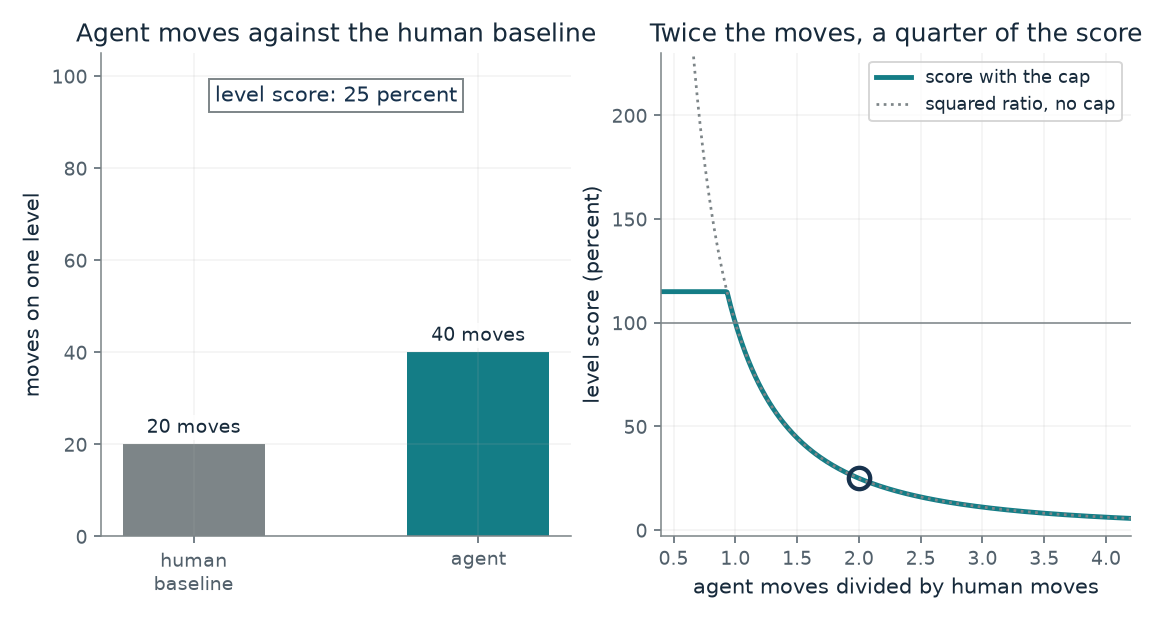

- **Agent moves:** 40
- **Moves divided by human baseline:** 2
- **Squared ratio (h/a)^2:** 0.25
- **Level score (percent):** 25

With 40 moves against a human baseline of 20, the squared ratio is 0.25 and the level scores 25 percent.

s = min((h/a)^2, 1.15) = min((20/40)^2, 1.15) = min(0.25, 1.15) = 0.25.

In [2]:
figure, values, explanation = level_picture(**{'agent_moves': 40, 'status': 'finished'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What does a level score reward?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Agent's moves on the level = 40, Did the agent finish the level? = finished: Twice the baseline gives (1/2)^2, a quarter, so 25 percent. Try 15 moves: the squared ratio is 1.78, but the cap holds it at 115 percent, and anything under about 18.7 moves is capped the same.

**Takeaway:** The squared ratio punishes extra moves quickly, and the cap stops fewer moves from buying an unlimited bonus.

**Why it matters:** A benchmark score is a rule applied to move counts. Reading the rule shows what a number such as 99.95 percent rewards: completing levels and doing it efficiently.

**In brains and behavior:** The baseline is the upper-median move count of people who finished the level. About 500 members of the public were tested, and an environment was kept only if at least two of them solved every level on first exposure, which is a selection rule, not a finding that any person solves any environment.

**In machines:** The agent's move count comes from one run of the harness and model. The score compares counts of actions and says nothing about how the agent decided them.

**Where it applies:** The score depends on move counts alone, the human baseline is the upper median of the people who finished that level, and a level the agent does not finish scores zero. The benchmark total also depends on weights and a completion term, shown in the next demonstration.

**Check your understanding:** The baseline is 20 moves and an agent takes 25. What is the level score?

<details><summary>Show the answer</summary>

(20/25)^2 = 0.64, so 64 percent.

</details>

*Source: Chapter 33, 99.95 percent combines completion and move efficiency. Book formula, the per-level score the chapter gives for ARC-AGI-3. The chapter notes that the technical report prints the cap in a different place from its prose and an inspected software version; this follows the chapter's formula. The 20-move baseline is a constructed number: the score depends only on the ratio.*

## C33-D02: Why is an environment score the smaller of two averages?

In a five-level environment weighted by level number, how do finishing fewer levels and using fewer moves combine?

Each finished level scores by its move ratio, capped; each unfinished level scores zero. The two averages weight levels by their number, so later levels matter more. Completion is the share of that weight finished. Efficiency can exceed completion only through the bonus above 100 percent, and taking the smaller removes that bonus.

$$
\text{score}=\min\!\Big(\sum_l w_l\,s_l,\ \sum_l w_l\,c_l\Big),\qquad w_l=\frac{l}{\sum_k k}
$$

**Symbols:** w_l: the weight of level l: its level number divided by the sum of level numbers (15 for five levels); s_l: the level score from the previous demonstration, zero if not finished; c_l: 1 if the agent finished level l, otherwise 0

**Predict before looking:** An agent finishes only levels 1 and 2 of 5, using fewer moves than the human baseline on both. Predict whether its efficiency bonus raises its environment score above the completed share.

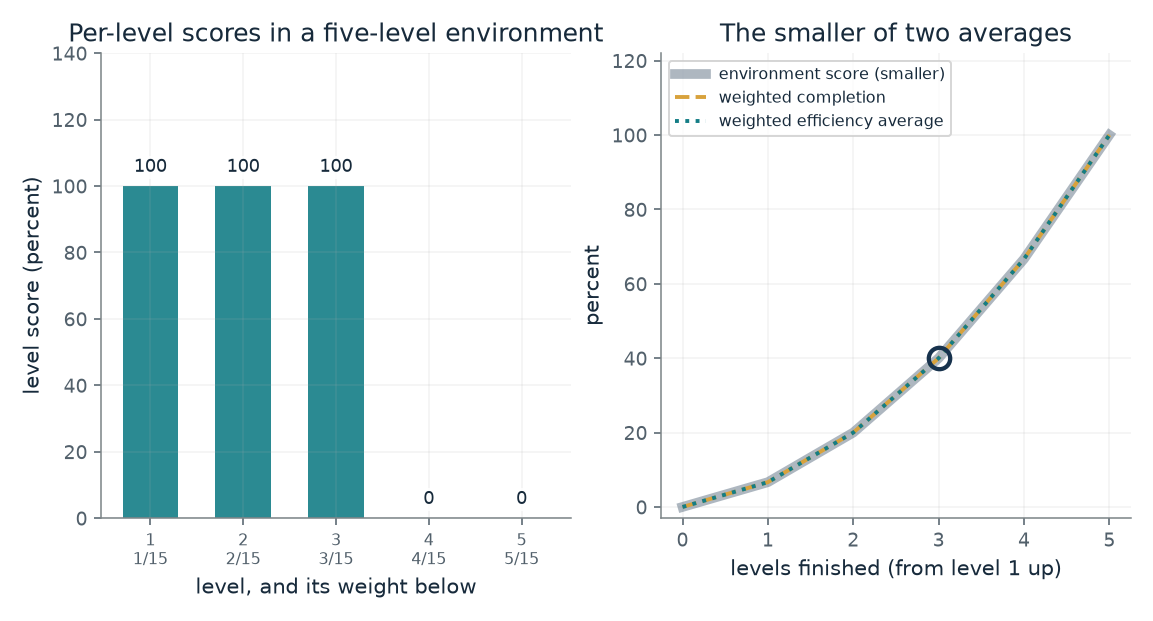

- **Weighted efficiency average (percent):** 40
- **Weighted completion (percent):** 40
- **Environment score (percent):** 40
- **Which is smaller:** neither (equal)

Finishing 3 of 5 levels at 1 of the human move count, each finished level scores 1. Efficiency averages 40 percent and completion 40 percent, so the environment scores 40.

Weights are the level numbers over 15. Efficiency = sum of weight x level score = 0.4. Completion = sum of weight x finished = 0.4. Score = min(0.4, 0.4) = 0.4.

In [3]:
figure, values, explanation = environment_picture(**{'levels_done': 3, 'move_ratio': 1.0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why is an environment score the smaller of two averages?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Levels finished (from level 1 up) = 2, Agent moves divided by human moves = 0.8: At 0.8 times the human moves each finished level scores 1.15, so efficiency averages 23 percent. Completion is 3/15, 20 percent, and the environment score takes the smaller, 20. Efficiency cannot buy credit for levels never finished.

**Takeaway:** The smaller of the two averages means finished levels count at full weight, and the cap prevents a bonus on the early levels from standing in for the later ones.

**Why it matters:** A headline total hides how completion and efficiency were combined. Knowing the rule shows why 99.95 percent needs nearly every level finished, and finished efficiently.

**In brains and behavior:** Later levels count more because early levels should contribute less. That choice is the designers', not a finding about human skill.

**In machines:** The score is computed from the agent's recorded runs. It is a specification of the scoring rule applied to action counts, not a model of how the agent works.

**Where it applies:** Five levels, the agent finishes levels 1 up to k, and every finished level uses the same move ratio. The benchmark total then averages such environment scores, which is not shown. The cap placement follows the chapter's formula.

**Check your understanding:** An agent finishes levels 1 to 3 of 5 at exactly the human move count. What is its environment score?

<details><summary>Show the answer</summary>

Each finished level scores 1, so efficiency and completion are both (1 + 2 + 3)/15 = 0.4, and the score is 40 percent.

</details>

*Source: Chapter 33, 99.95 percent combines completion and move efficiency. The environment score and level weights are the chapter's rule: the smaller of the weighted efficiency average and the weighted fraction of levels completed, with the level number as the weight. The chapter does not say how many levels an environment has; the five-level environment and the common move ratio on every finished level are constructed here.*

## C33-D03: Can one model have two scores on the same set?

GPT-6 Astra scored 62.7 and 99.95 percent on the same set. How do the harness and the effort setting each enter?

The same model was run under two wrappers at six effort settings. The Standard harness score depends strongly on effort, and is not even steady across settings, since none beats low. The Adapter scores sit between 96.7 and 99.95 throughout. Comparing the two at each setting, as the right panel does, removes the effort mismatch of the two best entries.

$$
\text{gap}(e)=S_{\text{Adapter}}(e)-S_{\text{Standard}}(e)
$$

**Symbols:** e: the effort setting: none, low, medium, high, xhigh or max; S_Standard(e), S_Adapter(e): the best entry's score under each harness at effort e, in percent; gap(e): the difference in points at the same effort

**Predict before looking:** The chapter's two best entries are at different effort levels (max for Standard, high for Adapter). Predict whether the Provider Adapter would still lead at every effort setting.

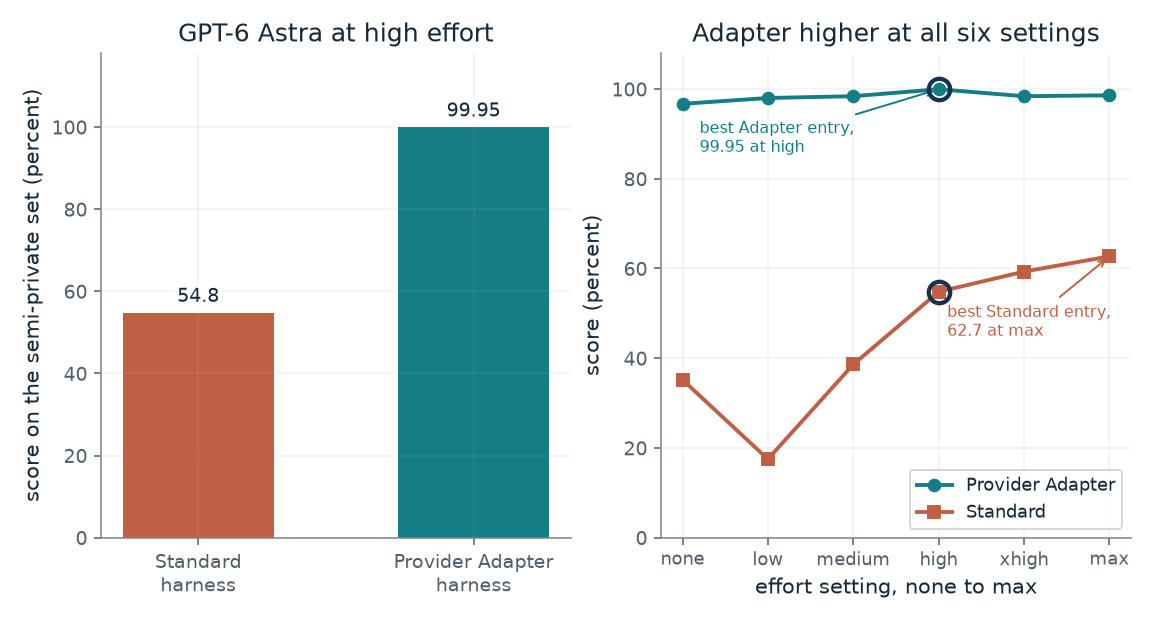

- **Standard harness (percent):** 54.8
- **Provider Adapter harness (percent):** 99.95
- **Gap at this effort (points):** 45.15
- **Adapter higher at all six settings:** yes

At high effort the Standard harness scored 54.8 and the Provider Adapter 99.95, a gap of 45.15 points. The Adapter is higher at all six settings, and each entry is a single run on one date, so a score needs its harness, set and effort.

Gap = 99.95 - 54.8 = 45.15 points. The best entries differ in effort: Standard 62.7 at max, Adapter 99.95 at high, a gap of 37.25 that mixes the harness effect with the effort setting.

In [4]:
figure, values, explanation = harness_picture(**{'effort': 'high'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Can one model have two scores on the same set?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Effort setting = max: At max effort the Standard harness scored 62.7 and the Provider Adapter 98.6, a gap of 35.9 points. The Adapter is higher at all six settings, and the Standard scores range from 17.5 to 62.7 while the Adapter never fell below 96.7.

**Takeaway:** The Adapter leads at every effort setting, so the 99.95 versus 62.7 headline is not only an effort effect, but a number still has to travel with its harness, set and date.

**Why it matters:** A single score can describe the model together with its software. The foundation treats the two harnesses as separate questions, so quoting one without the other can mislead.

**In brains and behavior:** The human baseline behind both scores came from about 500 members of the public, not chosen for puzzle-solving skill. A score near 100 indicates high completion and action efficiency under this scoring rule.

**In machines:** The harness decides what the model carries from step to step. In the Standard harness it carries notes it chose to write; the Provider Adapter uses the provider's own memory features. The effort level is a dial the tester sets.

**Where it applies:** The numbers are the chapter's as of 2 November 2026. Each is one run, so no spread is available. The gap at the same effort isolates the harness more than the headline pair does, but it does not show why the harness matters.

**Check your understanding:** At which effort setting is the gap between the harnesses largest, and how large is it?

<details><summary>Show the answer</summary>

At low effort: 98.0 minus 17.5 is 80.5 points. The smallest gap is at max effort, 35.9 points.

</details>

*Source: Chapter 33, 99.95 percent combines completion and move efficiency. The twelve scores are those in the chapter's source note, from the foundation's leaderboard data file of 2 November 2026: each entry is the best of its harness at that effort, on the semi-private set, a single run. The web page shows the 99.95 entry as 99.9 (data value 0.99946). The companion did not check them against the live leaderboard; standings move.*

## C33-D04: Can the order of two children flip with no change in their scores?

Two children, P and Q, have made-up scores on two groups of tasks. How does the weight on each group decide who leads?

The weighted average is a straight line in the weight. P's line starts at 35 and ends at 85, Q's starts at 75 and ends at 45, so the lines cross exactly where the weight is one half. Left of the crossing Q leads, and right of it P leads. The scores themselves never move.

$$
S=\sum_{t=1}^{N}w_t r_t,\qquad \sum_{t=1}^{N}w_t=1
$$

**Symbols:** r_t: the score on task group t; w_t: its weight, nonnegative; N: the number of groups (two here); S: the weighted average

**Predict before looking:** With equal weights both children average 60. Predict who leads if the first group counts four times as much, and the weight at which the order flips.

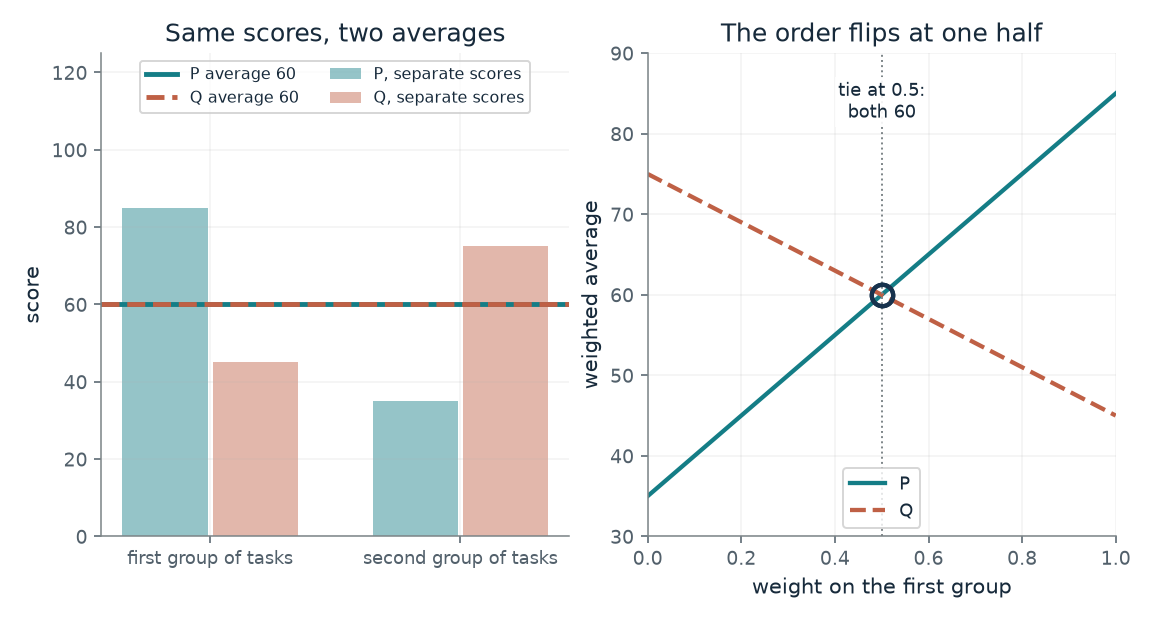

- **P weighted average:** 60
- **Q weighted average:** 60
- **Ahead:** neither (tie)
- **Weight on the second group:** 0.5

With weight 0.5 on the first group and 0.5 on the second, P averages 60 and Q 60. The separate scores never change; the weights decide the order, because they record which question was asked.

P = 0.5 x 85 + 0.5 x 35 = 60. Q = 0.5 x 45 + 0.5 x 75 = 60. The difference is 80 x w - 40 = 0, which is zero at w = 0.5.

In [5]:
figure, values, explanation = weighted_picture(**{'weight_first': 0.5})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Can the order of two children flip with no change in their scores?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Weight on the first group = 0.8: With 0.8 on the first group P averages 75 and Q 51, as in the chapter. At 0.5 they tie at 60, and below 0.5 Q leads: at 0.2 Q has 69 and P 45.

**Takeaway:** Neither average is wrong. The weights record which question was asked, and changing them can reverse a ranking.

**Why it matters:** A leaderboard is a ranked table of weighted averages. When two systems have different profiles, their order depends on weights someone chose, so the profile should travel with the total.

**In brains and behavior:** A person's test total is a weighted sum of results on separate tasks. Two people can have the same total and different profiles; the numbers here are made up.

**In machines:** A benchmark such as ARC-AGI-3 states its weights openly: level 3 counts three times level 1. Changing the weights could change the order of systems.

**Where it applies:** Two groups on a common scale, nonnegative weights that sum to one. The scores are made up and say nothing about any child.

**Check your understanding:** With weight 0.6 on the first group, what do P and Q average, and who leads?

<details><summary>Show the answer</summary>

P = 0.6 x 85 + 0.4 x 35 = 65 and Q = 0.6 x 45 + 0.4 x 75 = 57. P leads by 8.

</details>

*Source: Chapter 33, A total is a weighted average. The chapter's illustration with made-up scores: P scores 85 and 35, Q scores 45 and 75. The averages 60 and 60, 75 and 51, 45 and 69 are the chapter's.*

## C33-D05: Can a one-factor table arise with no shared die?

Tests that are sums of overlapping dice correlate. Can the correlations look like one common factor even when no die is common to every test?

Each die adds to every test that uses it, so two tests correlate in proportion to the dice they share. When tests use different shares of a large pool, the pattern of correlations has the same shape as a one-factor table, where the correlation is a product of two loadings. The fit improves as the pool grows and the random wobble shrinks.

$$
X_i=\lambda_i\,g+\epsilon_i\ \Rightarrow\ r_{ij}=\lambda_i\lambda_j,\qquad r_{ij}=\frac{n_{ij}}{\sqrt{n_i n_j}}\ \text{for sums of dice}
$$

**Symbols:** X_i: the score on test i; lambda_i: the loading of test i on the common factor g; n_i: the number of dice in test i; n_ij: the number of dice that tests i and j share; r_ij: the correlation between tests i and j

**Predict before looking:** Predict whether ten tests built with no die shared by all of them can have a correlation table that a single common factor fits closely, and what happens as the pool of dice grows.

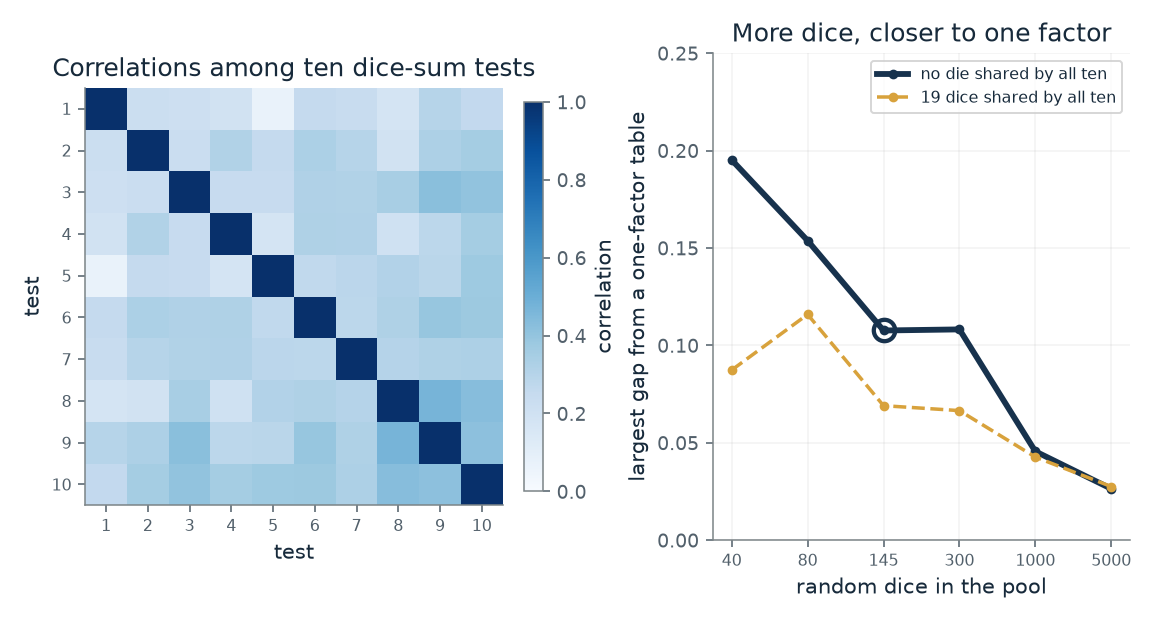

- **Dice entering all ten tests:** 0
- **Most tests any one die enters:** 8
- **Mean correlation between tests:** 0.296
- **Largest gap from a one-factor table:** 0.108

With 145 random dice and 0 shared, 0 dice enter all ten tests, the mean correlation is 0.296, and the best one-factor table misses by at most 0.108. A one-factor table summarizes these correlations although no die is common to all tests.

Test i uses each die with chance 0.15 to 0.45 (ten values). Correlation = shared dice / sqrt(dice in one x dice in the other). A one-factor table has correlation = loading i x loading j; the best fit leaves a largest gap of 0.108 (seeded draw).

In [6]:
figure, values, explanation = dice_picture(**{'dice': 145, 'shared': 0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Can a one-factor table arise with no shared die?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Random dice in the pool = 5000, Dice shared by all ten tests = 0: With 5000 random dice and none shared by all tests, no die enters all ten, the correlations are all positive, and a one-factor table fits them within about 0.03. The shared-dice case is nearly as close, so the fit does not tell the two apart.

**Takeaway:** A one-factor fit is a summary of the correlations, not a finding that a common cause lies behind them.

**Why it matters:** A single factor from scores that rise together can come from a shared cause, from overlapping causes, or from skills that help each other. The data alone, as Thomson showed, did not separate the first two.

**In brains and behavior:** Spearman reported positive correlations among all nine pairs of senses and gradings in 24 schoolchildren, the smallest 0.25 and the average 0.38. His 1904 argument is a proposal of a common factor, and he called it rough.

**In machines:** Language models that share training material and fail together could show a common factor from shared exposure. Kim and colleagues found two wrong models picked the same wrong option about 60 percent of the time, against one third for independent choices, and the cause is not established.

**Where it applies:** Independent fair dice that add in each test, which the chapter says psychological factors need not do. The simulation shows only that a table of positive correlations can be summarized by one factor without a common cause. It does not say anything about intelligence, and the chapter lists a common factor, overlapping causes and mutual benefit as three accounts that fit the same data.

**Check your understanding:** In the left panel, does a correlation between two tests tell you which dice they share, or only how many?

<details><summary>Show the answer</summary>

Only how many: the correlation is the number of shared dice divided by the square root of the product of the two test sizes. Many different assignments of dice give the same table.

</details>

*Source: Chapter 33, Thomson's dice: a one-factor table with no shared die. A constructed simulation in the spirit of the chapter's Thomson example, with disclosed seeds. It is not Thomson's table: each die enters each of ten tests with a chance between 0.15 and 0.45, and the 19 shared dice and 145 dice echo the numbers in the chapter and its source note. The one-factor equation is a later form, not in Spearman's 1904 paper.*

## C33-D06: What does a classifier that never read the premise reveal?

A classifier that saw only the hypothesis got 67.0 percent right. How does that split a test into Easy and Hard, and what does the split do to a model's overall score?

Easy items are those the blind classifier got right, so their share of the test is its accuracy, 67.0 percent. The full model's overall score is then an average of its Easy and Hard scores with those weights, which is the same weighted average as in the previous demonstrations. The numbers fit, so the split is consistent with the reported scores.

$$
S_{\text{overall}}=e\,S_{\text{Easy}}+(1-e)\,S_{\text{Hard}}
$$

**Symbols:** e: the share of test items the blind classifier got right, which are the Easy items; S_Easy, S_Hard: the full model's scores on the Easy and Hard items: 93.4 and 72.7 percent; S_overall: the full model's overall score, reported as 86.5 percent

**Predict before looking:** Using only the 67.0 percent and the model's 93.4 and 72.7, predict the full model's overall score before looking.

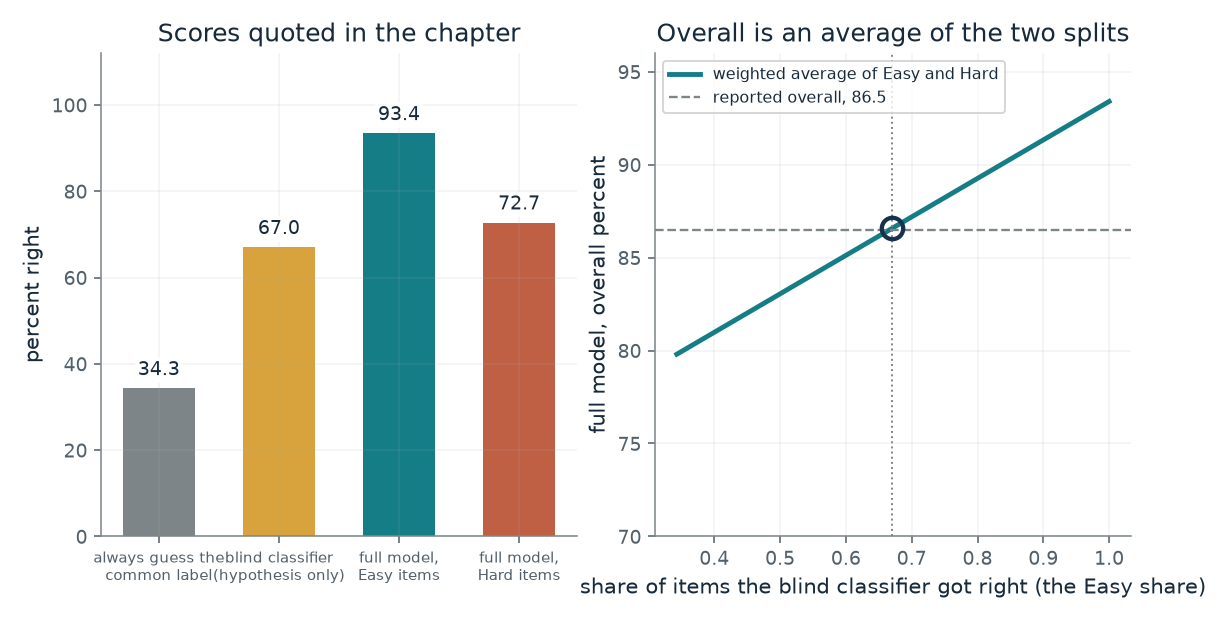

- **Easy share:** 0.67
- **Hard share:** 0.33
- **Weighted overall (percent):** 86.57
- **Reported overall (percent):** 86.5

If the blind classifier got 67 percent right, Easy items are that share and Hard the rest, so a model scoring 93.4 on Easy and 72.7 on Hard averages 86.57. At 67.0 percent this is 86.57, within 0.1 of the reported 86.5.

Overall = share Easy x 93.4 + share Hard x 72.7 = 0.67 x 93.4 + 0.33 x 72.7 = 86.57. Solving 86.5 = e x 93.4 + (1 - e) x 72.7 gives e = 0.667.

In [7]:
figure, values, explanation = blind_picture(**{'blind_right': 0.67})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What does a classifier that never read the premise reveal?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Share of items the blind classifier got right = 0.67: At 0.67, Easy items are two thirds of the set, and the weighted average is 86.57, within rounding of the reported 86.5. Move the slider to see how the overall score would change if the blind classifier had done worse or better.

**Takeaway:** The reported overall score is what the Easy and Hard scores give when the blind classifier's accuracy sets the weights, so the three numbers are consistent.

**Why it matters:** A score can reward a shortcut instead of the skill the test names. A blind baseline is a quick way to see how much of a test can be passed without the skill, and how a split of the test can change the story.

**In brains and behavior:** Binet and Simon met a human version: some children always chose the line on one side of the sheet, which earns one right in three. The habit buys no good score.

**In machines:** The blind classifier, fastText, learned which words in a hypothesis go with a label, for example words such as nobody and never for a contradiction. The authors say such artifacts do not render any particular example incorrect.

**Where it applies:** Easy items are exactly those the blind classifier got right, all scores are on one test set, and the reported percentages are rounded. The blind classifier shows only that the data allow a shortcut. Whether the full model used it is a separate question, and because Hard is defined by the blind classifier's failures, the split itself can contribute to the drop.

**Check your understanding:** If the blind classifier had been right on only 50 percent of items, with the same Easy and Hard scores, what would the overall score be?

<details><summary>Show the answer</summary>

0.5 x 93.4 + 0.5 x 72.7 = 83.05, about 83.1 percent.

</details>

*Source: Chapter 33, A classifier that never saw the premise got 67.0 percent right. The scores 34.3, 67.0, 93.4, 72.7 and 86.5 percent are quoted from the chapter (Gururangan and colleagues, 2018). The identity that the Easy share equals the blind classifier's accuracy follows from the chapter's definition of Easy; the weighted-average check against 86.5 is the companion's own, and it assumes all the scores come from the same test set.*

## Bring it to your own question

Ask which tasks, with what weights, on which set, under which harness and effort, on which date. Ask for the profile before the total. Check whether a part of the input alone predicts the answer, whether scores that rise together could come from overlapping causes, and whether the comparison with people was matched. Say that a total is not the thing it names.

Use the `mmi-ch33-what-counts` skill to choose a relevant equation, work with your inputs, and interpret the result. The skill should explain the assumptions and distinguish an illustration from evidence about your particular situation.